# 03 — Baseline Model & Setup Validasi

**Tujuan.** Membangun baseline yang jujur dan terukur sebagai pembanding notebook 04.

**Pilihan algoritma.** LightGBM (gradient boosting) dipilih karena:
1. target kategorikal 7 kelas dengan fitur campuran numerik + kategorikal kardinalitas
   tinggi — LightGBM menangani keduanya secara native (tanpa one-hot);
2. data ±1,2 juta baris × ±140 fitur, hanya 2 core CPU → boosting berbasis histogram jauh
   lebih murah daripada model yang butuh matriks padat;
3. metrik macro F1 dapat dioptimalkan lewat bobot kelas dan penyesuaian probabilitas.

**Validasi.** Hold-out terstratifikasi 88/12 (bukan k-fold penuh) karena biaya komputasi
2 core; 149 ribu baris validasi cukup untuk estimasi macro F1 yang stabil dan dipakai
sebagai early-stopping set. Split dilakukan **setelah** fitur dibangun dan hanya memakai
fitur (bukan target), sehingga tidak ada kebocoran.

In [1]:
import sys, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import polars as pl
import matplotlib.pyplot as plt
%matplotlib inline

warnings.filterwarnings("ignore")
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 120)
pd.set_option("display.max_rows", 100)

# root proyek = folder terdekat ke atas yang berisi src/ dan data/
BASE = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "src").is_dir() and (p / "data").is_dir())
sys.path.insert(0, str(BASE))

import time
from sklearn.metrics import (f1_score, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, log_loss,
                             precision_score, recall_score)

from src.data_loader import PROCESSED_DIR, TARGET, CLASSES
from src.models import PARAMS, load_matrices, split_indices, class_weights, train_model
from src.utils import set_seed, evaluate, print_report

set_seed()
K = len(CLASSES)

In [2]:
# ---- muat matriks fitur + encoding kategorikal ----
d = load_matrices()
tr, te, y = d["tr"], d["te"], d["y"]
print("distribusi target:", dict(zip(CLASSES, np.bincount(y, minlength=K))))

idx_tr, idx_va = split_indices(y)
y_tr, y_va = y[idx_tr], y[idx_va]
tr_part = tr.iloc[idx_tr].reset_index(drop=True)
va_part = tr.iloc[idx_va].reset_index(drop=True)
del tr, te
print(f"train {tr_part.shape} | valid {va_part.shape}")

FEATS = list(tr_part.columns)
CAT_USE = [c for c in d["cat_cols"] if c in FEATS]

# baseline: tanpa target encoding, tetap memakai ID mentah sebagai kategorikal
w_class = class_weights(y_tr, K)
print("bobot kelas:", {c: round(float(w), 3) for c, w in zip(CLASSES, w_class)})

BASE_PARAMS = dict(PARAMS)
model_base = train_model(tr_part, va_part, y_tr, y_va, FEATS, CAT_USE,
                         params=BASE_PARAMS, n_rounds=300,
                         weights=w_class, early_stopping=40)

  dimuat: train (1243617, 199) | test (362245, 198)  [52.0s]
17 kolom kategorikal, 105 kolom numerik
distribusi target: {'normal': np.int64(473531), 'konfirmasi_alamat': np.int64(272911), 'tertunda_operasional': np.int64(185496), 'gagal_antar_awal': np.int64(124341), 'retur_pengirim': np.int64(87740), 'rusak_perjalanan': np.int64(61942), 'klaim_hilang': np.int64(37656)}
train (1094382, 122) | valid (149235, 122)
bobot kelas: {'normal': 0.375, 'konfirmasi_alamat': 0.651, 'tertunda_operasional': 0.958, 'gagal_antar_awal': 1.429, 'retur_pengirim': 2.025, 'rusak_perjalanan': 2.868, 'klaim_hilang': 4.718}
Training until validation scores don't improve for 40 rounds
[50]	valid_0's multi_logloss: 1.24241
[100]	valid_0's multi_logloss: 1.21944
[150]	valid_0's multi_logloss: 1.22417
Early stopping, best iteration is:
[111]	valid_0's multi_logloss: 1.21895
  selesai: 111 iterasi terbaik  [2168.6s]


In [3]:
p_va = model_base.predict(va_part[FEATS], num_iteration=model_base.best_iteration)
pred_va = p_va.argmax(1)

f1_macro = f1_score(y_va, pred_va, average="macro")
print("BASELINE (tanpa target encoding, tanpa tuning pengali)")
for k, v in evaluate(y_va, pred_va, p_va).items():
    print(f"  {k:12s}: {v}")
print()
print_report(y_va, pred_va, CLASSES)

BASELINE (tanpa target encoding, tanpa tuning pengali)
  macro_f1    : 0.50274
  weighted_f1 : 0.60411
  accuracy    : 0.58561
  log_loss    : 1.12428

                      precision    recall  f1-score   support

              normal     0.8400    0.6353    0.7234     56824
   konfirmasi_alamat     0.6539    0.5675    0.6077     32749
tertunda_operasional     0.6698    0.6989    0.6840     22260
    gagal_antar_awal     0.3674    0.3915    0.3791     14921
      retur_pengirim     0.2873    0.4299    0.3444     10529
    rusak_perjalanan     0.2994    0.5225    0.3807      7433
        klaim_hilang     0.2904    0.6417    0.3999      4519

            accuracy                         0.5856    149235
           macro avg     0.4869    0.5553    0.5027    149235
        weighted avg     0.6440    0.5856    0.6041    149235



,kelas,n_valid,precision,recall,f1
0,normal,56824,0.8400,0.6353,0.7234
1,konfirmasi_alamat,32749,0.6539,0.5675,0.6077
2,tertunda_operasional,22260,0.6698,0.6989,0.6840
3,gagal_antar_awal,14921,0.3674,0.3915,0.3791
4,retur_pengirim,10529,0.2873,0.4299,0.3444
5,rusak_perjalanan,7433,0.2994,0.5225,0.3807
6,klaim_hilang,4519,0.2904,0.6417,0.3999


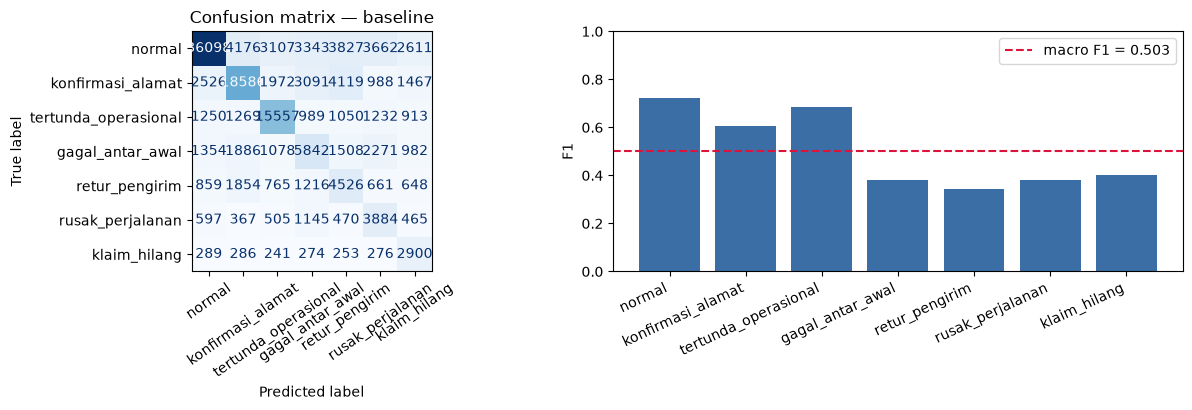

In [4]:
per_class = pd.DataFrame({
    "kelas": CLASSES,
    "n_valid": np.bincount(y_va, minlength=K),
    "precision": precision_score(y_va, pred_va, average=None, labels=range(K), zero_division=0),
    "recall": recall_score(y_va, pred_va, average=None, labels=range(K), zero_division=0),
    "f1": f1_score(y_va, pred_va, average=None, labels=range(K), zero_division=0),
})
display(per_class.round(4))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
ConfusionMatrixDisplay.from_predictions(y_va, pred_va, display_labels=CLASSES,
                                        xticks_rotation=35, ax=axes[0], colorbar=False,
                                        cmap="Blues")
axes[0].set_title("Confusion matrix — baseline")
axes[1].bar(per_class["kelas"], per_class["f1"], color="#3b6ea5")
axes[1].axhline(f1_macro, color="crimson", ls="--", label=f"macro F1 = {f1_macro:.3f}")
axes[1].set_ylim(0, 1); axes[1].set_ylabel("F1"); axes[1].legend()
plt.setp(axes[1].get_xticklabels(), rotation=25, ha="right")
plt.tight_layout(); plt.show()

,fitur,gain,gain_pct
1,courier_id,2.364048e+06,20.89
2,hub_id,1.349265e+06,11.92
38,cus_complaint,1.036461e+06,9.16
37,cus_addr_q,1.034837e+06,9.14
39,co_hub,7.869316e+05,6.95
41,co_score,4.871845e+05,4.30
7,declared_value,4.077587e+05,3.60
98,first_hub,3.703579e+05,3.27
58,q_mean,3.195822e+05,2.82
31,log_value,2.747816e+05,2.43


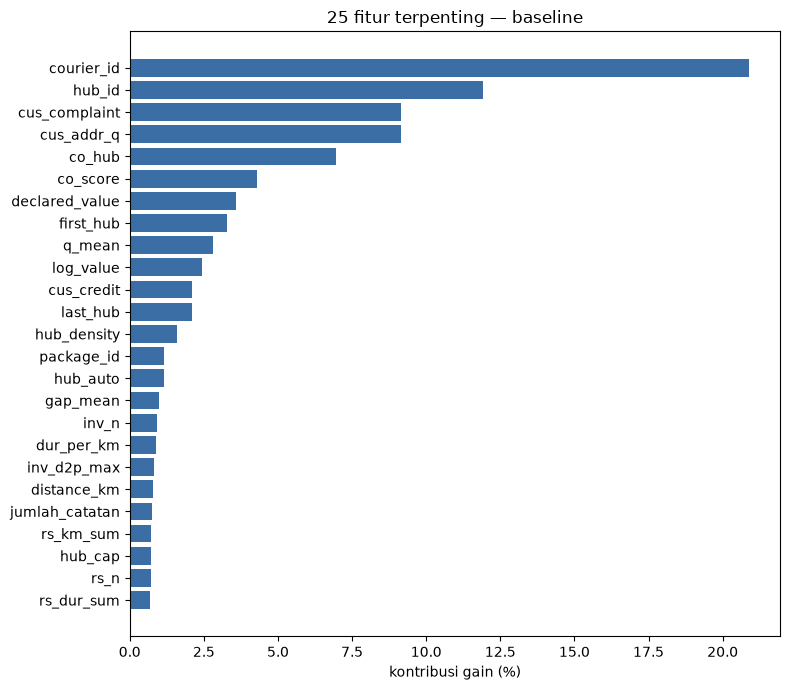

In [5]:
imp = (pd.DataFrame({"fitur": model_base.feature_name(),
                     "gain": model_base.feature_importance("gain")})
       .sort_values("gain", ascending=False))
imp["gain_pct"] = (imp["gain"] / imp["gain"].sum() * 100).round(2)
display(imp.head(25))

top = imp.head(25).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(top["fitur"], top["gain_pct"], color="#3b6ea5")
ax.set_xlabel("kontribusi gain (%)"); ax.set_title("25 fitur terpenting — baseline")
plt.tight_layout(); plt.show()

## Kesimpulan baseline

Baseline memberi patokan macro F1 yang bisa dibandingkan langsung dengan pendekatan di
notebook 04. Dua kelemahan yang terlihat dari confusion matrix dan importance:

1. **ID mentah kardinalitas tinggi** (`customer_id` 539 ribu nilai, `courier_id` 24 ribu)
   dipakai sebagai kategorikal — LightGBM hanya bisa memanfaatkan sebagian kecilnya dan
   berisiko menghafal.
2. **Kelas minoritas** masih tertinggal F1-nya meski sudah diberi bobot kelas; keputusan
   `argmax` belum tentu optimal untuk macro F1.

→ Notebook 04 mengatasi keduanya: target encoding out-of-fold untuk ID, lalu tuning
pengali probabilitas per kelas.